# Pearson Regression

Seberapa kuat dua kumpulan data berhubungan? **Koefisien korelasi Pearson** ($r$) menjawabnya dengan satu angka antara $-1$ dan $1$.
Notebook ini mengerjakan [Pearson Regression](https://github.com/florinpop17/app-ideas/blob/master/Projects/1-Beginner/Pearson-Regression-App.md) dari app-ideas.

**Aturan spesifikasi:** semua perhitungan ditulis sendiri, tanpa paket. Rumusnya ada di `pearson.py` (dengan unit test).
`numpy` dan `matplotlib` di notebook ini hanya untuk **membandingkan** hasil dan **menggambar**, bukan untuk menghitung.

## 1. Rumus

Untuk pasangan pengamatan $(x_i, y_i)$ dengan rata-rata $\bar{x}$ dan $\bar{y}$:

$$
r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \cdot \sum (y_i - \bar{y})^2}}
$$

- $r = 1$: naik bersama secara sempurna. $r = -1$: satu naik, satu turun, secara sempurna. $r \approx 0$: tidak ada hubungan **linear**.
- Simpangan baku yang dipakai adalah simpangan baku **sampel** (pembagi $n-1$).
- Garis regresi $y = ax + b$ dengan $a = \dfrac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sum (x_i-\bar{x})^2}$ dan $b = \bar{y} - a\bar{x}$.
- Tafsiran tiga tingkat dari spesifikasi memakai ambang konvensi: $|r| < 0.3$ *No correlation*, $0.3 \le |r| < 0.7$ *Neutral*, $|r| \ge 0.7$ *Some correlation*. Ambang ini kesepakatan, bukan hukum matematika.

In [1]:
import matplotlib.pyplot as plt
import numpy as np          # hanya untuk membandingkan hasil
import pandas as pd         # hanya untuk menampilkan tabel

from pearson import (Observations, linear_regression, mean, pearson_r, std_dev, summarize)

plt.rcParams.update({"figure.figsize": (6, 4), "axes.spines.top": False, "axes.spines.right": False})

## 2. Hitung langkah demi langkah

Contoh kecil: 5 hari, suhu (°C) dan jumlah es krim terjual.

In [2]:
suhu  = [24, 27, 29, 31, 34]
terjual = [20, 31, 38, 50, 61]

mx, my = mean(suhu), mean(terjual)
tabel = pd.DataFrame({"x": suhu, "y": terjual})
tabel["x - rata2 x"] = tabel["x"] - mx
tabel["y - rata2 y"] = tabel["y"] - my
tabel["(dx)(dy)"] = tabel["x - rata2 x"] * tabel["y - rata2 y"]
tabel["dx²"] = tabel["x - rata2 x"] ** 2
tabel["dy²"] = tabel["y - rata2 y"] ** 2
print(f"rata-rata x = {mx}, rata-rata y = {my}")
tabel

rata-rata x = 29.0, rata-rata y = 40.0


,x,y,x - rata2 x,y - rata2 y,(dx)(dy),dx²,dy²
0,24,20,-5.0,-20.0,100.0,25.0,400.0
1,27,31,-2.0,-9.0,18.0,4.0,81.0
2,29,38,0.0,-2.0,-0.0,0.0,4.0
3,31,50,2.0,10.0,20.0,4.0,100.0
4,34,61,5.0,21.0,105.0,25.0,441.0


In [3]:
sxy, sxx, syy = tabel["(dx)(dy)"].sum(), tabel["dx²"].sum(), tabel["dy²"].sum()
print(f"Σ(dx)(dy) = {sxy:.2f}   Σdx² = {sxx:.2f}   Σdy² = {syy:.2f}")
print(f"r = {sxy:.2f} / √({sxx:.2f} × {syy:.2f}) = {sxy / (sxx * syy) ** 0.5:.4f}")
print(f"fungsi pearson_r  : {pearson_r(suhu, terjual):.4f}")
print(f"pembanding numpy  : {np.corrcoef(suhu, terjual)[0, 1]:.4f}")

Σ(dx)(dy) = 243.00   Σdx² = 58.00   Σdy² = 1026.00
r = 243.00 / √(58.00 × 1026.00) = 0.9961
fungsi pearson_r  : 0.9961
pembanding numpy  : 0.9961


## 3. Fungsi untuk menampilkan hasil dan grafik sebaran

Suhu vs es krim terjual
  jumlah pasangan : 5
  rata-rata       : x = 29.00, y = 40.00
  simpangan baku  : x = 3.81, y = 16.02
  korelasi r      : +0.9961  ->  Some correlation (positif)


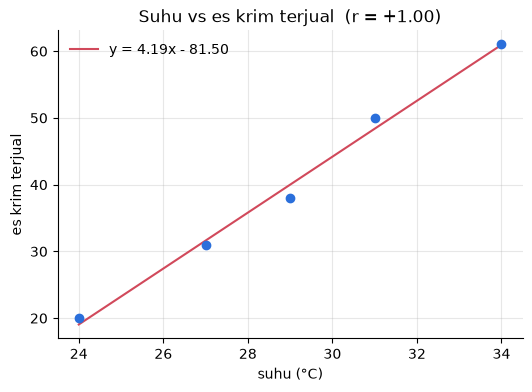

In [4]:
def analisis(xs, ys, judul, xlabel="x", ylabel="y"):
    hasil = summarize(xs, ys)
    print(f"{judul}")
    print(f"  jumlah pasangan : {hasil['n']}")
    print(f"  rata-rata       : x = {hasil['mean_x']:.2f}, y = {hasil['mean_y']:.2f}")
    print(f"  simpangan baku  : x = {hasil['std_x']:.2f}, y = {hasil['std_y']:.2f}")
    print(f"  korelasi r      : {hasil['r']:+.4f}  ->  {hasil['interpretation']}")
    fig, ax = plt.subplots()
    ax.scatter(xs, ys, color="#2a6fdb", zorder=3)
    lo, hi = min(xs), max(xs)
    ax.plot([lo, hi], [hasil["slope"] * lo + hasil["intercept"], hasil["slope"] * hi + hasil["intercept"]],
            color="#d1495b", label=f"y = {hasil['slope']:.2f}x {'+' if hasil['intercept'] >= 0 else '-'} {abs(hasil['intercept']):.2f}")
    ax.set(title=f"{judul}  (r = {hasil['r']:+.2f})", xlabel=xlabel, ylabel=ylabel)
    ax.legend(frameon=False)
    ax.grid(alpha=.3)
    plt.show()
    return hasil

_ = analisis(suhu, terjual, "Suhu vs es krim terjual", "suhu (°C)", "es krim terjual")

## 4. Tiga bentuk hubungan

Contoh dari spesifikasi: suhu dan harga mobil (*tidak* berhubungan), ditambah hubungan negatif.
Data dibuat dengan `random.Random(seed)` supaya hasilnya sama setiap kali notebook dijalankan.

Suhu vs harga mobil
  jumlah pasangan : 30
  rata-rata       : x = 27.99, y = 314.27
  simpangan baku  : x = 3.90, y = 90.43
  korelasi r      : +0.2737  ->  No correlation


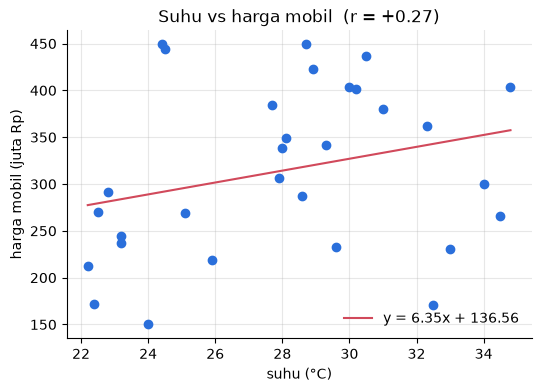

In [5]:
import random
rng = random.Random(11)

suhu_harian = [round(rng.uniform(22, 35), 1) for _ in range(30)]
harga_mobil = [round(rng.uniform(150, 450)) for _ in range(30)]          # juta rupiah, tidak terkait suhu
_ = analisis(suhu_harian, harga_mobil, "Suhu vs harga mobil", "suhu (°C)", "harga mobil (juta Rp)")

Usia mobil vs harga bekas
  jumlah pasangan : 12
  rata-rata       : x = 6.50, y = 259.25
  simpangan baku  : x = 3.61, y = 85.65
  korelasi r      : -0.9975  ->  Some correlation (negatif)


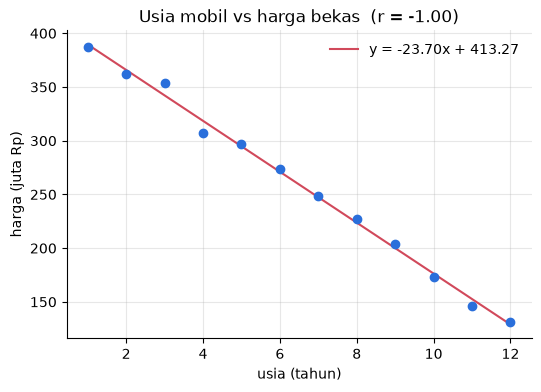

In [6]:
usia_mobil = list(range(1, 13))
harga_bekas = [round(400 - 22 * u + rng.gauss(0, 12)) for u in usia_mobil]
_ = analisis(usia_mobil, harga_bekas, "Usia mobil vs harga bekas", "usia (tahun)", "harga (juta Rp)")

## 5. Hati-hati: angka yang sama, gambar berbeda

**Kuartet Anscombe** adalah empat kumpulan data dengan rata-rata, simpangan baku, $r$, dan garis regresi yang hampir identik, tetapi bentuknya sangat berbeda.
Satu angka $r$ tidak pernah cukup: **selalu lihat grafiknya**.

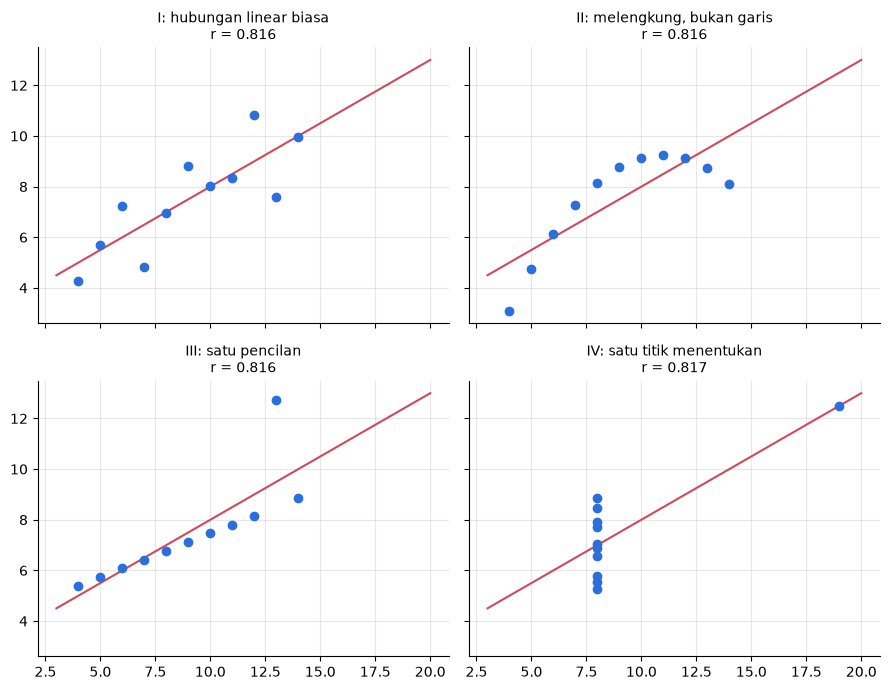

In [7]:
x123 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
set_data = {
    "I: hubungan linear biasa":  (x123, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II: melengkung, bukan garis": (x123, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III: satu pencilan": (x123, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV: satu titik menentukan": ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for ax, (nama, (xs, ys)) in zip(axes.flat, set_data.items()):
    a, b = linear_regression(xs, ys)
    ax.scatter(xs, ys, color="#2a6fdb", zorder=3)
    ax.plot([3, 20], [a * 3 + b, a * 20 + b], color="#d1495b")
    ax.set_title(f"{nama}\nr = {pearson_r(xs, ys):.3f}", fontsize=10)
    ax.grid(alpha=.3)
fig.tight_layout()
plt.show()

Keempatnya $r \approx 0.816$ dan garis $y \approx 0.5x + 3$. Hanya set I yang benar-benar cocok dengan "hubungan linear". Korelasi juga **bukan sebab-akibat**: es krim dan kasus tenggelam sama-sama naik di musim panas, tetapi es krim tidak menenggelamkan siapa pun.

## 6. Meniru panel input: Add, Calculate, dan pesan kesalahan

In [8]:
tabel_input = Observations()
for x, y in [("1", "2.1"), ("2", "3.9"), ("abc", "5"), ("3", "")]:
    ok = tabel_input.add(x, y)
    print(f"Add ({x!r}, {y!r}) -> {'ok' if ok else 'DITOLAK: ' + tabel_input.error} | Calculate aktif: {tabel_input.calculate_enabled}")

print()
tabel_input.add("3", "6.2")   # pasangan benar memulihkan tombol Calculate
print("Setelah pasangan valid, Calculate aktif:", tabel_input.calculate_enabled)
print(tabel_input.calculate())

Add ('1', '2.1') -> ok | Calculate aktif: False
Add ('2', '3.9') -> ok | Calculate aktif: True
Add ('abc', '5') -> DITOLAK: x: 'abc' bukan bilangan real (gunakan titik untuk desimal, misalnya 3.5) | Calculate aktif: False
Add ('3', '') -> DITOLAK: y: kosong | Calculate aktif: False

Setelah pasangan valid, Calculate aktif: True
{'n': 3, 'mean_x': 2.0, 'mean_y': 4.066666666666666, 'std_x': 1.0, 'std_y': 2.055075018906447, 'r': 0.9975304945757417, 'interpretation': 'Some correlation (positif)', 'slope': 2.05, 'intercept': -0.033333333333333215}


## 7. Memuat pengamatan dari berkas CSV (bonus)

Jam belajar vs nilai (dari CSV)
  jumlah pasangan : 7
  rata-rata       : x = 4.00, y = 69.00
  simpangan baku  : x = 2.16, y = 12.60
  korelasi r      : +0.9922  ->  Some correlation (positif)


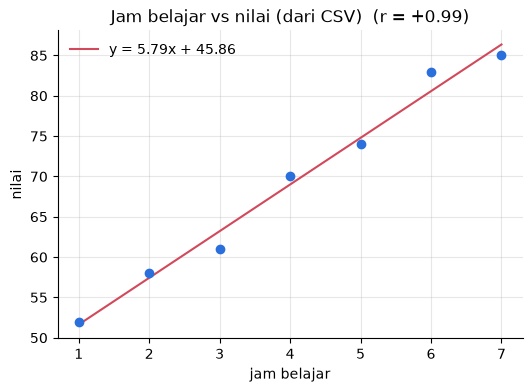

In [9]:
import os, tempfile
from pearson import load_csv

with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, "data.csv")
    with open(path, "w", encoding="utf-8") as f:
        f.write("belajar_jam,nilai\n1,52\n2,58\n3,61\n4,70\n5,74\n6,83\n7,85\n")
    xs, ys = load_csv(path)

_ = analisis(xs, ys, "Jam belajar vs nilai (dari CSV)", "jam belajar", "nilai")

Di terminal, hal yang sama: `python pearson.py data.csv`. Baris judul dilewati otomatis, dan baris yang salah ditolak dengan nomor barisnya.

## Rangkuman

- $r$ mengukur kekuatan dan arah hubungan **linear**, bukan sebab-akibat.
- Ambang tafsiran adalah konvensi; jangan membaca terlalu jauh dari satu angka.
- Selalu gambar datanya (kuartet Anscombe).
- Rumus ditulis sendiri dan diverifikasi terhadap `numpy` di unit test pada 100 data acak.